In [38]:
import pandas as pd
import numpy as np
import missingno as msno

pd.set_option('display.float_format', lambda x: '{:.0f}'.format(x))

### Загрузка данных

In [2]:
df_2020 = pd.read_parquet('https://s3.twcstorage.ru/9573b473-48bf-4029-9142-f52b4b06b7a3/share/moex_tqbr_daily/v=20261109/data/year=2020/part.parquet')
df_2021 = pd.read_parquet('https://s3.twcstorage.ru/9573b473-48bf-4029-9142-f52b4b06b7a3/share/moex_tqbr_daily/v=20261109/data/year=2021/part.parquet')
df_2022 = pd.read_parquet('https://s3.twcstorage.ru/9573b473-48bf-4029-9142-f52b4b06b7a3/share/moex_tqbr_daily/v=20261109/data/year=2022/part.parquet')
df_2023 = pd.read_parquet('https://s3.twcstorage.ru/9573b473-48bf-4029-9142-f52b4b06b7a3/share/moex_tqbr_daily/v=20261109/data/year=2023/part.parquet')
df_2024 = pd.read_parquet('https://s3.twcstorage.ru/9573b473-48bf-4029-9142-f52b4b06b7a3/share/moex_tqbr_daily/v=20261109/data/year=2024/part.parquet')
df_2025 = pd.read_parquet('https://s3.twcstorage.ru/9573b473-48bf-4029-9142-f52b4b06b7a3/share/moex_tqbr_daily/v=20261109/data/year=2025/part.parquet')
df_2026 = pd.read_parquet('https://s3.twcstorage.ru/9573b473-48bf-4029-9142-f52b4b06b7a3/share/moex_tqbr_daily/v=20261109/data/year=2026/part.parquet')

In [ ]:
shares = pd.concat([df_2020, df_2021, df_2022, df_2023, df_2024, df_2025, df_2026],ignore_index=True)


In [4]:
shares.info()

<class 'pandas.DataFrame'>
RangeIndex: 472985 entries, 0 to 472984
Data columns (total 24 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   BOARDID                  472985 non-null  str    
 1   TRADEDATE                472985 non-null  object 
 2   SHORTNAME                472985 non-null  str    
 3   SECID                    472985 non-null  str    
 4   NUMTRADES                472985 non-null  int64  
 5   VALUE                    472985 non-null  float64
 6   OPEN                     439228 non-null  float64
 7   LOW                      439228 non-null  float64
 8   HIGH                     439228 non-null  float64
 9   LEGALCLOSEPRICE          467704 non-null  float64
 10  WAPRICE                  439423 non-null  float64
 11  CLOSE                    439228 non-null  float64
 12  VOLUME                   472985 non-null  int64  
 13  MARKETPRICE2             333020 non-null  float64
 14  MARKETPRICE3   

### Предобработка

In [5]:
shares.describe()

,NUMTRADES,VALUE,OPEN,LOW,HIGH,LEGALCLOSEPRICE,WAPRICE,CLOSE,VOLUME,MARKETPRICE2,MARKETPRICE3,ADMITTEDQUOTE,MP2VALTRD,MARKETPRICE3TRADESVALUE,ADMITTEDVALUE,WAVAL,TRADINGSESSION,TRENDCLSPR
count,4.729850e+05,4.729850e+05,4.392280e+05,4.392280e+05,4.392280e+05,4.677040e+05,4.394230e+05,4.392280e+05,4.729850e+05,333020.000000,449725.000000,198657.000000,4.729850e+05,4.729850e+05,2.028810e+05,4.429080e+05,472985.0,441031.000000
mean,7.077774e+03,3.541475e+08,2.190025e+03,2.154013e+03,2.225912e+03,7.687636e+03,2.192117e+03,2.187548e+03,2.810474e+08,2436.741822,2436.310797,2267.989870,3.092193e+08,2.980130e+08,3.294573e+08,5.508048e+06,3.0,-0.337768
std,2.618539e+04,1.760177e+09,1.268641e+04,1.259361e+04,1.277437e+04,2.314915e+05,1.269380e+04,1.268176e+04,5.831924e+09,10783.889710,11881.655322,10610.247155,1.769856e+09,1.468847e+09,2.323789e+09,1.396296e+08,0.0,19.879421
min,0.000000e+00,0.000000e+00,2.000000e-03,1.710000e-03,2.140000e-03,2.080000e-03,1.970000e-03,2.080000e-03,0.000000e+00,0.001970,0.001970,0.002080,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.0,-100.000000
25%,4.700000e+01,3.226950e+05,8.000000e+00,7.820000e+00,8.160000e+00,8.300000e+00,7.995000e+00,8.000000e+00,2.142000e+03,10.475500,8.020000,6.120000,0.000000e+00,5.216000e+05,0.000000e+00,0.000000e+00,3.0,-1.100000
50%,3.390000e+02,3.393221e+06,9.150000e+01,8.990000e+01,9.300000e+01,9.756000e+01,9.150000e+01,9.140000e+01,9.570000e+04,107.200000,92.850000,78.350000,3.150547e+06,3.071782e+06,1.153415e+06,0.000000e+00,3.0,-0.030000
75%,4.153000e+03,6.767369e+07,7.050000e+02,6.912000e+02,7.184250e+02,7.510000e+02,7.050000e+02,7.040000e+02,1.530000e+06,719.500000,727.200000,596.700000,6.010157e+07,5.830968e+07,2.641168e+07,0.000000e+00,3.0,0.930000
max,3.535228e+06,2.385837e+11,2.310600e+06,2.310600e+06,2.310600e+06,1.430000e+07,2.310600e+06,2.310600e+06,7.032681e+11,370000.000000,370000.000000,179300.000000,4.070000e+11,1.653794e+11,4.070000e+11,8.130666e+09,3.0,12140.000000


In [6]:
shares['TRADEDATE'] = pd.to_datetime(shares['TRADEDATE'])

<Axes: >

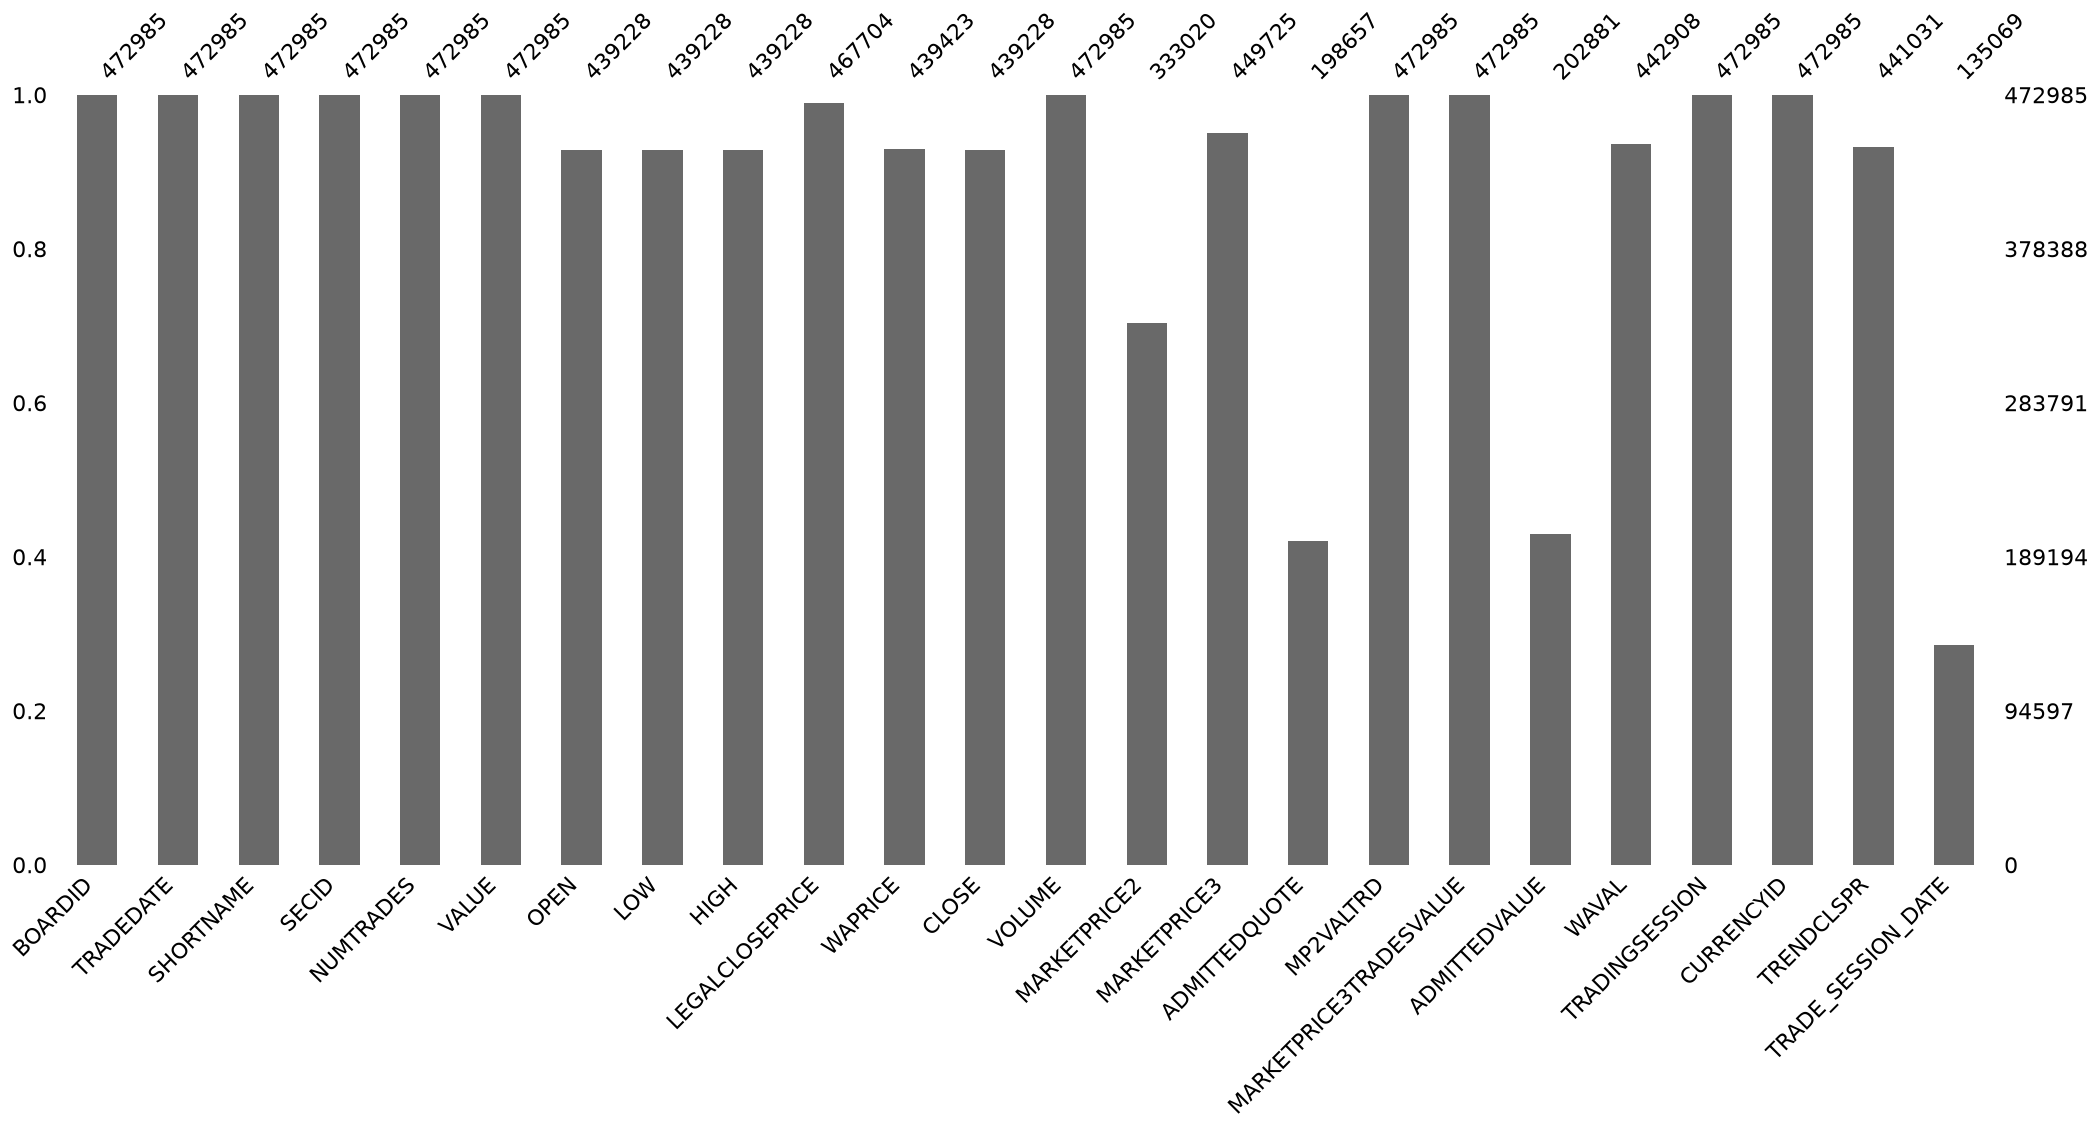

In [7]:
msno.bar(shares)

Для заполнения пропусков в колонке `CLOSE` (цены закрытия) используется метод Forward Fill. Его суть в том, что он заменяет отсутствующее значение последней известной ценой того же инструмента. Выбор данного метода обусловлен необходимостью сохранить непрерывную последовательность наблюдений без удаления торговых дат.

Первоначальное заполнение пропущенных цен закрытия медианой приводило к искажению исторической динамики стоимости акций.

In [8]:
print('Пропусков CLOSE:', shares['CLOSE'].isna().sum())

Пропусков CLOSE: 33757


In [ ]:
shares.sort_values(['SECID', 'TRADEDATE'], inplace=True)

shares['CLOSE_FILLED'] = (shares.groupby('SECID')['CLOSE'].ffill())

In [10]:
len(shares['CLOSE_FILLED'])

472985

### Скользящие волатильности

Для оценки изменения стоимости акций рассчитывается простая дневная доходность.

Формула:

$$
r_{i,t} = \frac{P_{i,t} - P_{i,t-1}}{P_{i,t-1}}
$$

где:

- $r_{i,t}$ — доходность акции $i$ в момент $t$;
- $P_{i,t}$ — цена закрытия акции $i$ в момент $t$;
- $P_{i,t-1}$ — цена закрытия на предыдущую дату наблюдения.

Полученная доходность необходима для оценки исторической волатильности

In [11]:
shares['RETURNS'] = shares.groupby('SECID')['CLOSE'].pct_change(fill_method=None)

Для оценки рыночного риска акций используется скользящая историческая волатильность. Чем выше волатильность, тем сильнее могут изменяться цены акций и тем выше неопределённость будущей стоимости позиции,а скользящее окно позволяет учитывать изменение рыночного риска во времени.

Расчет производится по формуле:

$$
\sigma_{i,t} =
\sqrt{
\frac{1}{n-1}
\sum_{k=1}^{n}
(r_{i,t-k+1}-\bar{r}_{i,t})^2
}
$$

где:

- $\sigma_{i,t}$ — историческая волатильность акции $i$;
- $n$ — количество наблюдений в скользящем окне;
- $r_{i,t}$ — дневная доходность акции;
- $\bar{r}_{i,t}$ — средняя доходность за рассматриваемый период.

Для годового пересчёта используется формула:

$$
\sigma_{\text{annual}} = \sigma_{\text{daily}}\sqrt{252}
$$


Были выбраны следующие параметры:

- Размер скользящего окна — 252 наблюдения, как как приближение количества торговых дней за год
- Минимальное количество наблюдений — 200
- Коэффициент годового пересчёта — $\sqrt{252}$

Минимальный размер выборки установлен для того, чтобы не рассчитывать волатильность по слишком короткой истории

Также, в начале для каждой акции ещё недостаточно данных для вычисления стандартного отклонения доходности за выбранный период. Поэтому первые 199 наблюдений доходности имеют значение NaN в колонке `VOLATILITY`. Наблюдения с неизвестной волатильностью не используются при формировании инвестиционных портфелей.

In [ ]:
shares['VOLATILITY'] = (shares.groupby('SECID')['RETURNS'].transform(lambda x: x.rolling(252, min_periods=200).std()) * np.sqrt(252))

### Ликвидность

Помимо волатильности, при оценке риска учитывалась ликвидность инструмента. Ликвидность характеризует возможность покупки или продажи актива без существенного влияния на его рыночную цену. Низкая ликвидность увеличивает риск инвестора, поскольку продажа значительного объёма акций может потребовать дополнительного времени или привести к неблагоприятной цене исполнения сделки.

В качестве приближённого показателя ликвидности используется медианный дневной денежный оборот.
Для каждой акции рассчитывается медиана показателя `VALUE` за последние 252 наблюдения:

$$
L_{i,t} =
\operatorname{Median}
(V_{i,t-n+1},\ldots,V_{i,t})
$$

где:

- $L_{i,t}$ — показатель ликвидности акции;
- $V_{i,t}$ — дневной денежный оборот в рублях;
- $n$ — размер скользящего окна.

Аналогично тому, как считалась волатильность, использование скользящего окна позволяет учитывать изменение ликвидности во времени.

In [ ]:
shares['LIQUIDITY'] = (shares.groupby('SECID')['VALUE'].transform(lambda x: x.rolling(252, min_periods=200).median()))

In [15]:
shares.tail()

,BOARDID,TRADEDATE,SHORTNAME,SECID,NUMTRADES,VALUE,OPEN,LOW,HIGH,LEGALCLOSEPRICE,...,ADMITTEDVALUE,WAVAL,TRADINGSESSION,CURRENCYID,TRENDCLSPR,TRADE_SESSION_DATE,CLOSE_FILLED,RETURNS,VOLATILITY,LIQUIDITY
472980,TQBR,2026-10-29,ЗВЕЗДА ао,ZVEZ,25,320690.0,5.41,5.29,5.42,5.36,...,NaN,0.0,3,SUR,-1.30,2026-10-29,5.33,-0.012963,0.510428,459245.0
472981,TQBR,2026-10-30,ЗВЕЗДА ао,ZVEZ,14,230160.0,5.35,5.29,5.40,5.29,...,NaN,0.0,3,SUR,0.75,2026-10-30,5.37,0.007505,0.510253,459245.0
472982,TQBR,2026-11-02,ЗВЕЗДА ао,ZVEZ,11,133660.0,5.37,5.32,5.42,5.32,...,NaN,0.0,3,SUR,-0.93,2026-11-02,5.32,-0.009311,0.510269,449835.0
472983,TQBR,2026-11-03,ЗВЕЗДА ао,ZVEZ,19,186040.0,5.32,5.26,5.38,5.33,...,NaN,0.0,3,SUR,1.13,2026-11-03,5.38,0.011278,0.510321,444160.0
472984,TQBR,2026-11-05,ЗВЕЗДА ао,ZVEZ,28,278310.0,5.28,5.27,5.39,5.30,...,NaN,0.0,3,SUR,-0.19,2026-11-05,5.37,-0.001859,0.510317,438330.0


### Присвоение класса риска

Для количественной оценки риска каждому наблюдению присваиваются два балла: один на основании исторической волатильности, второй — на основании ликвидности.

Оба показателя оцениваются по трёхбалльной шкале:

- **1 балл** — низкий риск.
- **2 балла** — средний риск.
- **3 балла** — высокий риск.

Границы категорий представлены в таблице:

$$
\begin{array}{|c|c|c|}
\hline
\text{Балл риска} & \text{Волатильность} & \text{Ликвидность} \\
\hline
1 \text{ — низкий} & \leq 30\% & >10 \text{ млн руб.} \\
\hline
2 \text{ — средний} & 30\%-50\% & 1-10 \text{ млн руб.} \\
\hline
3 \text{ — высокий} & >50\% & \leq 1 \text{ млн руб.} \\
\hline
\end{array}
$$

**Для волатильности** зависимость прямая: чем выше стандартное отклонение доходности, тем выше оценка рыночного риска.

**Для ликвидности** зависимость обратная: чем ниже медианный дневной оборот, тем выше риск возникновения трудностей при продаже актива.

Таким образом, акция с относительно стабильной ценой может получить повышенную итоговую оценку риска, если она обладает низкой ликвидностью. Выбранные пороговые значения являются тестовыми и используются для первоначальной классификации инструментов.


После присвоения отдельных оценок рассчитывается интегральный показатель риска:

$$
R_{i,t}=0.7R_{\sigma,i,t}+0.3R_{L,i,t}
$$

где:

- $R_{i,t}$ — итоговая оценка риска акции $i$ на дату $t$;
- $R_{\sigma,i,t}$ — балл исторической волатильности;
- $R_{L,i,t}$ — балл риска ликвидности.


На основании итогового балла наблюдения распределяются по трём категориям риска:

- **Low:** $R \leq 1.5$
- **Medium:** $1.5 < R \leq 2.5$
- **High:** $R > 2.5$

Дополнительно введены ограничения: 

- при волатильности выше **50%** наблюдение обязательно относится к категории `high` независимо от итогового балла.

- При волатильности выше **100%** категория риска не присваивается, и такое наблюдение исключается из выборки для формирования новых портфелей.

При этом исторические данные сохраняются, поскольку одна и та же акция может иметь разные категории риска в разные периоды.

In [ ]:
shares['VOL_RISK'] = pd.cut(
    shares['VOLATILITY'],
    bins=[0, 0.3, 0.5, np.inf],
    labels=[1, 2, 3]
).astype('float')

shares['LIQ_RISK'] = pd.cut(
    shares['LIQUIDITY'],
    bins=[-np.inf, 1000000, 10000000, np.inf],
    labels=[3, 2, 1]
).astype('float')

shares['RISK_SCORE'] = (
    0.7 * shares['VOL_RISK'] +
    0.3 * shares['LIQ_RISK']
)

shares['RISK_LEVEL'] = pd.cut(
    shares['RISK_SCORE'],
    bins=[0, 1.5, 2.5, 3],
    labels=['low', 'medium', 'high']
)

shares.loc[shares['VOLATILITY'] > 0.5, 'RISK_LEVEL'] = 'high' # заносим наблюдение в группу с высоким риском, если олатильность больше 50%

shares.loc[shares['VOLATILITY'] > 1,'RISK_LEVEL'] = np.nan # наблюдение не получает категорию риска и не будет участвовать в генерации портфелей, если волатильность больше 100%


In [23]:
shares.groupby('RISK_LEVEL')['SECID'].nunique()

RISK_LEVEL
low       161
medium    296
high      237
Name: SECID, dtype: int64

In [ ]:
print('Описательные статистики групп по волатильности')
shares.groupby('RISK_LEVEL')['VOLATILITY'].agg(['count', 'min', 'median', 'max'])

Описательные статистики групп по волатильности


,count,min,median,max
RISK_LEVEL,,,,
low,56075,0.077700,0.251662,0.299997
medium,190258,0.110146,0.378424,0.499994
high,110842,0.500001,0.630742,0.999991


In [25]:
print('Описательные статистики групп по ликивдности')
shares.groupby('RISK_LEVEL')['LIQUIDITY'].agg(['count', 'min', 'median', 'max'])

Описательные статистики групп по ликивдности


,count,min,median,max
RISK_LEVEL,,,,
low,56075,1000168.6,1.128646e+08,1.575512e+10
medium,190258,13886.0,2.754599e+06,1.589635e+10
high,110842,18437.0,1.632155e+06,1.496291e+10


In [26]:
shares.tail()

,BOARDID,TRADEDATE,SHORTNAME,SECID,NUMTRADES,VALUE,OPEN,LOW,HIGH,LEGALCLOSEPRICE,...,TRENDCLSPR,TRADE_SESSION_DATE,CLOSE_FILLED,RETURNS,VOLATILITY,LIQUIDITY,VOL_RISK,LIQ_RISK,RISK_SCORE,RISK_LEVEL
472980,TQBR,2026-10-29,ЗВЕЗДА ао,ZVEZ,25,320690.0,5.41,5.29,5.42,5.36,...,-1.30,2026-10-29,5.33,-0.012963,0.510428,459245.0,3.0,3.0,3.0,high
472981,TQBR,2026-10-30,ЗВЕЗДА ао,ZVEZ,14,230160.0,5.35,5.29,5.40,5.29,...,0.75,2026-10-30,5.37,0.007505,0.510253,459245.0,3.0,3.0,3.0,high
472982,TQBR,2026-11-02,ЗВЕЗДА ао,ZVEZ,11,133660.0,5.37,5.32,5.42,5.32,...,-0.93,2026-11-02,5.32,-0.009311,0.510269,449835.0,3.0,3.0,3.0,high
472983,TQBR,2026-11-03,ЗВЕЗДА ао,ZVEZ,19,186040.0,5.32,5.26,5.38,5.33,...,1.13,2026-11-03,5.38,0.011278,0.510321,444160.0,3.0,3.0,3.0,high
472984,TQBR,2026-11-05,ЗВЕЗДА ао,ZVEZ,28,278310.0,5.28,5.27,5.39,5.30,...,-0.19,2026-11-05,5.37,-0.001859,0.510317,438330.0,3.0,3.0,3.0,high


### Генерация портфелей

Генерация осуществляется методом Монте-Карло — многократным случайным формированием составов и весов инвестиционных портфелей.

Предусмотрены три типа портфелей:

1. Консервативный
2. Умеренный
3. Агрессивный

Они различаются распределением капитала между акциями разных категорий риска. Для каждого портфеля случайным образом выбирается заданное количество акций.

Выбор осуществляется из инструментов, удовлетворяющих следующим условиям:

- Акция присутствует в данных на дату формирования портфеля.
- Для неё рассчитана категория риска.
- Медианный дневной оборот составляет не менее 1 млн рублей.

### Моделирование весов
Для формирования весов используется распределение Дирихле.

Распределение позволяет генерировать случайные неотрицательные веса, сумма которых равна единице:

$$
w_i \geq 0,
\qquad
\sum_{i=1}^{N} w_i = 1
$$

Случайные веса генерируются отдельно внутри каждой категории риска, после чего масштабируются в соответствии с заданной долей капитала данной категории.

### Моделирование капитала
Также, дополнительно моделируется размер капитала инвестора.

Для генерации используется равномерное распределение:

$$
C \sim U(C_{\min},C_{\max})
$$

где:

- $C$ — капитал инвестора;
- $C_{\min}$ — минимальный размер капитала;
- $C_{\max}$ — максимальный размер капитала.

Равномерное распределение выбрано для упрощения первоначальной генерации. Это не утверждает, что капитал реальных инвесторов распределён равномерно.

После генерации капитала рассчитывается сумма, выделенная на каждую акцию:

$$
A_i = C \cdot w_i
$$

где:

- $A_i$ — сумма инвестиций в акцию;
- $C$ — общий капитал инвестора;
- $w_i$ — вес акции в портфеле.

Полученные суммы представляют собой планируемое распределение капитала без учёта комиссий, биржевых лотов и ограничений на исполнение сделок.

In [ ]:
def generate_portfolios(shares, n_portfolios=1000, n_stocks=9, min_capital=1_000_000, max_capital=5_000_000, date=None):

    '''
    Генерирует синтетические инвестиционные портфели методом Монте-Карло. Акции случайным образом выбираются из трёх категорий риска: low, medium и high. 
    Веса активов генерируются с помощью распределения Дирихле. 

    В генерации участвуют только акции с известной категорией риска и ликвидностью не менее 1 млн рублей.

    Количество акций внутри каждого портфеля фиксировано, но их состав и веса определяются случайным образом.
    '''
    rng = np.random.default_rng(42)

    if date is None:
        date = shares['TRADEDATE'].max()
    date = pd.to_datetime(date)

    available = shares.loc[
        (shares['TRADEDATE'] == date) &
        shares['RISK_LEVEL'].notna() &
        (shares['LIQUIDITY'] >= 1000000)
    ]

    portfolio_types = {
        'conservative': [0.7, 0.2, 0.1],
        'moderate': [0.2, 0.6, 0.2],
        'aggressive': [0.1, 0.2, 0.7]
    }
    risk_levels = ['low', 'medium', 'high']


    counts = np.full(3, n_stocks // 3)
    counts[:n_stocks % 3] += 1 # Распределение количества акций между тремя категориями риска

    groups = {risk: available.loc[available['RISK_LEVEL'] == risk, 'SECID'].unique().to_numpy() for risk in risk_levels} # Формирование списков доступных акций для каждой категории

    portfolios = []
    for portfolio_type, allocations in portfolio_types.items(): # Генерация портфелей каждого типа  
        selected = []
        weights = []
        risks = []
        for risk, allocation, n in zip(risk_levels, allocations, counts): # Случайный выбор акций и генерация весов внутри каждой категории риска

            tickers = groups[risk]

            random_matrix = rng.random((n_portfolios, len(tickers)))
            indices = np.argsort(random_matrix, axis=1)[:, :n]
            selected.append(tickers[indices]) # Выбор n случайных акций без повторений для каждого портфеля

            w = rng.dirichlet(np.ones(n), size=n_portfolios)
            weights.append(w * allocation) # Генерация весов с учётом доли капитала группы

            risks.extend([risk] * n)

        selected = np.hstack(selected)
        weights = np.hstack(weights) # Объединение выбранных акций и их весов

        capital = rng.uniform(min_capital, max_capital, size=n_portfolios) # Генерация случайного капитала инвесторов в заданном диапазоне

        df_portfolios = pd.DataFrame({
            'portfolio_id': np.repeat([f'{portfolio_type}_{i}' for i in range(n_portfolios)], n_stocks),
            'portfolio_type': portfolio_type,
            'date': date,
            'SECID': selected.ravel(),
            'weight': weights.ravel(),
            'risk_level': np.tile(risks, n_portfolios),
            'capital': np.repeat(capital, n_stocks)
        })

        df_portfolios['amount'] = (df_portfolios['weight'] * df_portfolios['capital'])
        portfolios.append(df_portfolios)


    portfolios = pd.concat(portfolios, ignore_index=True)

    return portfolios

In [ ]:
portfolios = generate_portfolios(shares, n_portfolios=1000, n_stocks=10, min_capital=1000000, max_capital=5000000)

In [56]:
portfolios

,portfolio_id,portfolio_type,date,SECID,weight,risk_level,capital,amount
0,conservative_0,conservative,2026-11-05,T,0,low,3559728,237768
1,conservative_0,conservative,2026-11-05,PIKK,0,low,3559728,669005
2,conservative_0,conservative,2026-11-05,GEMC,0,low,3559728,956467
3,conservative_0,conservative,2026-11-05,LEAS,0,low,3559728,628570
4,conservative_0,conservative,2026-11-05,BELU,0,medium,3559728,528759
...,...,...,...,...,...,...,...,...
29995,aggressive_999,aggressive,2026-11-05,FEES,0,medium,4612633,220716
29996,aggressive_999,aggressive,2026-11-05,KRKNP,0,medium,4612633,160988
29997,aggressive_999,aggressive,2026-11-05,MGKL,1,high,4612633,2609904
29998,aggressive_999,aggressive,2026-11-05,MFGSP,0,high,4612633,159750


In [41]:
portfolios.to_parquet(r'C:\Users\User\Downloads\portfolios.parquet', index=False)